<h1 style="color:#1F4E79;">DCWP Consumer Complaints Analysis</h1>

<p style="font-size:16px; color:#555;">
<b>Data Cleaning & Preparation</b><br>
Python • Pandas • Data Analytics
</p>

<hr style="border:1px solid #D9EAF7;">

<h2 style="color:#2F75B5;">1. Project Overview</h2>

This project analyzes consumer complaint records published by the New York City Department of Consumer and Worker Protection (DCWP).

The dataset contains information about consumer complaints, businesses, complaint categories, intake channels, complaint results, referrals, locations, and other related details.

The purpose of this project is to clean and prepare the dataset for further exploratory data analysis (EDA). Data cleaning is an important step because real-world datasets may contain missing values, inconsistent entries, duplicate records, incorrect data types, and other data-quality issues.

### Objectives of Data Cleaning

The main objectives of the data-cleaning process are:

- Understand the structure and contents of the dataset.
- Identify missing values and highly incomplete columns.
- Clean and convert financial values into suitable numeric formats.
- Convert date columns into proper datetime format.
- Identify and handle inconsistent or placeholder values.
- Standardize categorical data where appropriate.
- Correct data types for identifier and code-related columns.
- Check for duplicate records.
- Validate the final cleaned dataset.
- Save the cleaned dataset for further analysis.

The cleaned dataset will be used for the Exploratory Data Analysis (EDA) phase of the project.


<h2 style="color:#2F75B5;">2. Importing Required Libraries</h2>

The following Python libraries are used in this project:

- **Pandas** – for data loading, manipulation, cleaning, and analysis.
- **NumPy** – for handling missing values and numerical operations.
- **Matplotlib** – for creating visualizations.
- **Seaborn** – for statistical visualizations.

These libraries provide the basic tools required for the data-cleaning and analysis process.

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

<h2 style="color:#2F75B5;">3. Loading the Dataset</h2>

The raw consumer complaints dataset is stored as a CSV file in the project's `data/raw` folder.

The dataset is loaded into a Pandas DataFrame so that it can be inspected, cleaned, and prepared for further analysis.

The raw dataset is kept unchanged so that the original data remains available for reference and reproducibility.

In [4]:
df = pd.read_csv("../data/raw/DCWP_Consumer_Complaints_20260918.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


<h2 style="color:#2F75B5;">4. Initial Dataset Inspection</h2>

Before performing any cleaning operations, the dataset is inspected to understand its structure, size, columns, data types, and sample records.

This initial inspection helps identify potential data-quality issues that need to be addressed during the cleaning process.

**Preview of the Dataset**

The first few records are displayed to understand the structure and content of the dataset.

In [5]:
df.head()

,Record ID,Intake Date,Intake Channel,311 SR Number,Business Category,Complaint Code,Business Unique ID,Business Name,Result Date,Result,Referred To,Contract Cancelled Amount,Refund Amount,Address Type,Building Nbr,Street1,Street2,Street3,Unit Type,Apt/Suite,City,State,Postcode,Borough,Community Board,Council District,BIN,BBL,NTA,Census Block (2010),Census Tract (2010),Latitude,Longitude
0,000001-2026-CMPL,01/01/2026,311,311-25776008,Garage & Parking Lot,Non-Delivery of Goods - N01,BA-1758638-2026,PLATINUM PLUS GARAGE,02/01/2026,Requested Information Not Provided,NaN,NaN,NaN,Complete Address,350,E 30TH ST,NaN,NaN,NaN,NaN,NEW YORK,NY,10016,Manhattan,106.0,4.0,1020634.0,1.009358e+09,MN20,3000.0,70.0,40.741635,-73.976219
1,000002-2026-CMPL,01/01/2026,311,311-25776542,Tow Truck Company,Lost/Stolen/Damaged Property,BA-1758639-2026,Legacy Towing,02/01/2026,Requested Information Not Provided,NaN,NaN,NaN,Complete Address,13101,39TH AVE,NaN,NaN,NaN,NaN,FLUSHING,NY,11354,Queens,407.0,20.0,4112199.0,4.049630e+09,QN22,2008.0,871.0,40.758836,-73.835231
2,000003-2026-CMPL,01/01/2026,311,311-25776844,Specialized Vending License - MFV,Advertising/Misleading - A02,BA-1758640-2026,The flavor of the new yorm,01/02/2026,Insufficient Info Received,NaN,NaN,NaN,Complete Address,134,W 43RD ST,NaN,NaN,NaN,NaN,NEW YORK,NY,10036,Manhattan,105.0,4.0,1087268.0,1.009950e+09,MN17,1005.0,119.0,40.755920,-73.984606
3,000004-2026-CMPL,01/01/2026,Online,NaN,Garage & Parking Lot,Other - Z01,BA-1287019-2022,"LAUREATE GARAGE, LLC",02/15/2026,Requested Information Not Provided,NaN,NaN,NaN,Complete Address,2148,BROADWAY,NaN,NaN,NaN,NaN,NEW YORK,NY,10023,Manhattan,107.0,6.0,1088786.0,1.011678e+09,MN12,5002.0,163.0,40.781385,-73.981177
4,000005-2026-CMPL,01/01/2026,Online,NaN,Garage & Parking Lot,Non-Delivery of Service - N02,BA-1758642-2026,LAUREATE GARAGE LLC,02/15/2026,Requested Information Not Provided,NaN,NaN,NaN,Complete Address,NaN,2148 Broadway,NaN,NaN,NaN,NaN,New York,NY,10023,Manhattan,107.0,6.0,1088786.0,1.011678e+09,MN12,5002.0,163.0,40.781385,-73.981177


**Dataset Dimensions**

The dataset contains the following number of rows and columns.

In [6]:
df.shape

(76527, 33)

In [7]:
df.columns.tolist()

['Record ID',
 'Intake Date',
 'Intake Channel',
 '311 SR Number',
 'Business Category',
 'Complaint Code',
 'Business Unique ID',
 'Business Name',
 'Result Date',
 'Result',
 'Referred To',
 'Contract Cancelled Amount',
 'Refund Amount',
 'Address Type',
 'Building Nbr',
 'Street1',
 'Street2',
 'Street3',
 'Unit Type',
 'Apt/Suite',
 'City',
 'State',
 'Postcode',
 'Borough',
 'Community Board',
 'Council District',
 'BIN',
 'BBL',
 'NTA',
 'Census Block (2010)',
 'Census Tract (2010)',
 'Latitude',
 'Longitude']

In [8]:
df.dtypes

Record ID                     object
Intake Date                   object
Intake Channel                object
311 SR Number                 object
Business Category             object
Complaint Code                object
Business Unique ID            object
Business Name                 object
Result Date                   object
Result                        object
Referred To                   object
Contract Cancelled Amount     object
Refund Amount                 object
Address Type                  object
Building Nbr                  object
Street1                       object
Street2                       object
Street3                       object
Unit Type                     object
Apt/Suite                     object
City                          object
State                         object
Postcode                      object
Borough                       object
Community Board              float64
Council District             float64
BIN                          float64
B

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76527 entries, 0 to 76526
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Record ID                  76527 non-null  object 
 1   Intake Date                76527 non-null  object 
 2   Intake Channel             76527 non-null  object 
 3   311 SR Number              53763 non-null  object 
 4   Business Category          75129 non-null  object 
 5   Complaint Code             65750 non-null  object 
 6   Business Unique ID         74030 non-null  object 
 7   Business Name              73154 non-null  object 
 8   Result Date                76527 non-null  object 
 9   Result                     76527 non-null  object 
 10  Referred To                28002 non-null  object 
 11  Contract Cancelled Amount  46 non-null     object 
 12  Refund Amount              1509 non-null   object 
 13  Address Type               72887 non-null  obj

<h2 style="color:#2F75B5;">5. Missing Value Analysis</h2>

Missing values are common in real-world datasets. Before deciding how to handle them, the number and percentage of missing values in each column are examined.

This helps identify columns that are highly incomplete and determine whether the missing values should be removed, retained, or handled in another way.

In [10]:
missing_count = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
Contract Cancelled Amount,76481,99.939890
Street3,76386,99.815751
Refund Amount,75018,98.028147
Street2,73360,95.861591
Unit Type,72531,94.778314
Apt/Suite,69794,91.201798
Referred To,48525,63.408993
311 SR Number,22764,29.746364
BBL,15379,20.096175
BIN,15379,20.096175


<h3 style="color:#5B9BD5;">Removing Highly Sparse Columns</h3>

The following address-detail columns contained more than 90% missing values and were removed because they provided limited information for the analysis:

- Street2
- Street3
- Unit Type
- Apt/Suite

Financial columns with high missing values were retained because their available values may provide useful information.

**Handling Highly Sparse Columns**

Columns with extremely high proportions of missing values were removed when they provided limited analytical value for the project.

In [11]:
df.drop(
    columns=["Street2", "Street3", "Unit Type", "Apt/Suite"],
    inplace=True
)

print(df.shape)

(76527, 29)


<h2 style="color:#2F75B5;">6. Cleaning Financial Columns</h2>

The `Contract Cancelled Amount` and `Refund Amount` columns contain monetary values.

The values contain currency symbols and commas, which need to be removed before converting the columns into numeric format.

Missing values are retained because a missing amount does not necessarily mean that the amount was zero.

In [12]:
df[["Contract Cancelled Amount", "Refund Amount"]].describe()




,Contract Cancelled Amount,Refund Amount
count,46,1509
unique,44,607
top,"$3,000","$10,000"
freq,2,82


In [13]:
df[["Contract Cancelled Amount", "Refund Amount"]].head(20)


,Contract Cancelled Amount,Refund Amount
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


In [14]:
df["Contract Cancelled Amount"] = (
    df["Contract Cancelled Amount"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["Refund Amount"] = (
    df["Refund Amount"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

df["Contract Cancelled Amount"] = pd.to_numeric(
    df["Contract Cancelled Amount"],
    errors="coerce"
)

df["Refund Amount"] = pd.to_numeric(
    df["Refund Amount"],
    errors="coerce"
)

In [15]:
df[["Contract Cancelled Amount", "Refund Amount"]].dtypes

Contract Cancelled Amount    Int64
Refund Amount                Int64
dtype: object

In [16]:
df[["Contract Cancelled Amount", "Refund Amount"]].head(20)

,Contract Cancelled Amount,Refund Amount
0,<NA>,<NA>
1,<NA>,<NA>
2,<NA>,<NA>
3,<NA>,<NA>
4,<NA>,<NA>
5,<NA>,<NA>
6,<NA>,<NA>
7,<NA>,<NA>
8,<NA>,<NA>
9,<NA>,<NA>


<h2 style="color:#2F75B5;">7. Cleaning Date Columns</h2>

The `Intake Date` and `Result Date` columns contain dates in text format.



**Date Format Standardization**

The `Intake Date` and `Result Date` columns are converted to datetime format to enable accurate date-based analysis.







In [17]:
df["Intake Date"] = pd.to_datetime(
    df["Intake Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

df["Result Date"] = pd.to_datetime(
    df["Result Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

In [18]:
df[["Intake Date", "Result Date"]].dtypes

Intake Date    datetime64[ns]
Result Date    datetime64[ns]
dtype: object

<h3 style="color:#5B9BD5;">Checking Date Consistency</h3>

The `Result Date` should normally occur on or after the `Intake Date`.

Records where the `Result Date` occurs before the `Intake Date` are checked for possible date inconsistencies.

In [19]:
invalid_dates = df[df["Result Date"] < df["Intake Date"]]

invalid_dates[["Record ID", "Intake Date", "Result Date", "Result"]]

,Record ID,Intake Date,Result Date,Result
28866,042731-2024-CMPL,2024-07-27,2024-07-26,Referred
63892,10355-2023-CMPL,2023-07-27,2023-07-20,Advised to Sue - ATS


In [20]:
df.loc[df["Result Date"] < df["Intake Date"], "Result Date"] = pd.NaT

The two records with inconsistent date order were identified. Since the correct dates could not be determined from the available data, the inconsistent `Result Date` values were set to missing rather than assigning assumed dates.


<h2 style="color:#2F75B5;">8. Cleaning Categorical Columns</h2>

<h3 style="color:#5B9BD5;">Categorical Data Inspection</h3>

The categorical columns were inspected to identify inconsistent formatting, placeholder values, and unusual entries before applying appropriate cleaning operations.

In [21]:
df["City"].value_counts(dropna=False)

City
BROOKLYN            18322
NEW YORK            17890
BRONX                9504
NaN                  5928
STATEN ISLAND        1967
                    ...  
DURYEA                  1
COLORADO SPRINGS        1
Elche                   1
Louisville              1
Fordham Heights         1
Name: count, Length: 1382, dtype: int64

In [22]:
df["Intake Channel"].value_counts(dropna=False)

Intake Channel
311                 53771
Online              17524
Email/Fax            2634
Hardcopy             2073
Cloned                264
Phone                 245
Walk-In                11
External Affairs        5
Name: count, dtype: int64

In [23]:








df["State"].value_counts(dropna=False)

State
NY             70657
NaN             3721
NJ               384
CA               297
Outside USA      135
FL               133
TX               115
PA               112
WA                70
CO                69
MN                68
MA                67
IL                66
OH                57
VA                56
GA                53
SC                51
CT                46
DE                40
MI                39
UT                39
NC                37
NV                26
MO                23
TN                21
MD                16
IN                14
SD                13
AZ                13
WI                12
AR                11
OR                10
DC                 9
AL                 8
LA                 7
KS                 6
KY                 6
IA                 5
NH                 3
OK                 3
NE                 2
WV                 1
ID                 1
ME                 1
MS                 1
WY                 1
ND                 1
NM     

In [24]:
df["Borough"].value_counts(dropna=False)

Borough
Manhattan        19712
Brooklyn         19305
Queens           15394
Bronx             9954
NaN               9613
Staten Island     1983
Outside NYC        566
Name: count, dtype: int64

In [25]:
df["Result"].value_counts(dropna=False)

Result
Referred                                              25633
Requested Information Not Provided                    23658
Complaint Review Complete                             11060
Insufficient Info Received                             4885
No Jurisdiction                                        1919
Information Provided                                   1412
Advised to Sue - ATS                                   1302
Duplicate Complaint - DUP                              1051
Resolved and Consumer Satisfied - SPF                  1007
No Business Response - NVR                              996
Cash Amount - AMT                                       808
No Consumer Response - NCR                              696
Credit Card Refund and/or Contract Cancelled - CRC      399
No Satisfactory Agreement - NSA                         335
Business Reported                                       243
Referred to Outside - RTO                               217
Inspection Requested             

In [26]:
df["Address Type"].value_counts(dropna=False)

Address Type
Complete Address               69639
NaN                             3640
Cross Street (Intersection)     2859
Place (Landmark)                 239
Block                            142
P.O. Box                           8
Name: count, dtype: int64

In [27]:
df["Business Category"].value_counts(dropna=False)

Business Category
Other                                                       11105
Misc Non-Food Retail                                         6077
Tow Truck Company                                            5587
Restaurant                                                   3835
Supermarket                                                  3460
                                                            ...  
Collection Business Category                                    1
Gaming Cafe                                                     1
Amusement Device Portable                                       1
Motion Picture Operator - 123                                   1
Games of Chance - Raffle with Net Proceeds Under $30,000        1
Name: count, Length: 116, dtype: int64

In [28]:
df["Referred To"].value_counts(dropna=False)

Referred To
NaN                             48525
Other                            7484
NYC Department of Sanitation     3820
-                                2442
NYC Police Department            1833
                                ...  
INS-000895326                       1
INS-000886316                       1
INS-000890975                       1
INS-000886716                       1
INS-000974629                       1
Name: count, Length: 386, dtype: int64

<h3 style="color:#5B9BD5;">Handling Placeholder Values</h3>

Some categorical fields contain placeholder values such as `-`, `Unknown`, `No name`, `none`, and `0`.

These values do not represent meaningful information, so they are treated as missing values where appropriate.

In [29]:
(df == "-").sum().sort_values(ascending=False)



Referred To                  2442
Business Name                   8
Record ID                       0
City                            0
Latitude                        0
Census Tract (2010)             0
Census Block (2010)             0
NTA                             0
BBL                             0
BIN                             0
Council District                0
Community Board                 0
Borough                         0
Postcode                        0
State                           0
Building Nbr                    0
Street1                         0
Intake Date                     0
Address Type                    0
Refund Amount                   0
Contract Cancelled Amount       0
Result                          0
Result Date                     0
Business Unique ID              0
Complaint Code                  0
Business Category               0
311 SR Number                   0
Intake Channel                  0
Longitude                       0
dtype: Int64

In [30]:
df["Referred To"] = df["Referred To"].replace("-", "Not Specified")

df["Business Name"] = df["Business Name"].replace(
    ["-", "Unknown", "unknown", "No name", "no name", "none", "0"],
    np.nan
)

df["311 SR Number"] = df["311 SR Number"].replace("0", np.nan)

df["Building Nbr"] = df["Building Nbr"].replace("0", np.nan)

df["Street1"] = df["Street1"].replace("0", np.nan)

df["Postcode"] = df["Postcode"].replace("0", np.nan)

In [31]:
df[df["Business Name"] == "-"][["Business Name", "Business Category", "Result", "Referred To"]]

,Business Name,Business Category,Result,Referred To


<h3 style="color:#5B9BD5;">Standardizing City Names</h3>


City names were standardized to uppercase to maintain consistent formatting across the dataset.

In [32]:
df["City"] = df["City"].str.upper()

In [33]:
df[["City", "Business Name", "Referred To"]].head()


,City,Business Name,Referred To
0,NEW YORK,PLATINUM PLUS GARAGE,NaN
1,FLUSHING,Legacy Towing,NaN
2,NEW YORK,The flavor of the new yorm,NaN
3,NEW YORK,"LAUREATE GARAGE, LLC",NaN
4,NEW YORK,LAUREATE GARAGE LLC,NaN


In [34]:
id_columns = [
    "Record ID",
    "311 SR Number",
    "Business Unique ID",
    "Building Nbr",
    "Postcode",
    "Community Board",
    "Council District",
    "BIN",
    "BBL",
    "Census Block (2010)",
    "Census Tract (2010)"
]

df[id_columns].dtypes

Record ID               object
311 SR Number           object
Business Unique ID      object
Building Nbr            object
Postcode                object
Community Board        float64
Council District       float64
BIN                    float64
BBL                    float64
Census Block (2010)    float64
Census Tract (2010)    float64
dtype: object

<h2 style="color:#2F75B5;">9. Correcting Data Types</h2>
Some identifier and code-related columns are stored as numeric values.

These columns are identifiers rather than measurements, so they are converted to string format to preserve their values correctly.

In [35]:
id_numeric_columns = [
    "Community Board",
    "Council District",
    "BIN",
    "BBL",
    "Census Block (2010)",
    "Census Tract (2010)"
]

for column in id_numeric_columns:
    df[column] = df[column].astype("Int64").astype("string")

In [36]:
#Checking
df[id_numeric_columns].dtypes

Community Board        string[python]
Council District       string[python]
BIN                    string[python]
BBL                    string[python]
Census Block (2010)    string[python]
Census Tract (2010)    string[python]
dtype: object

<h2 style="color:#2F75B5;">10. Checking Duplicate Records</h2>

Duplicate records can affect the accuracy of analysis, so the dataset is checked for exact duplicate rows.

Records with the same `Record ID` are also examined separately because the same identifier may appear in multiple rows with different information.

In [37]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [38]:
print("Duplicate Record IDs:", df["Record ID"].duplicated().sum())

Duplicate Record IDs: 137


In [39]:
duplicate_ids = df[df["Record ID"].duplicated(keep=False)]

print("Rows with duplicate Record IDs:", len(duplicate_ids))

Rows with duplicate Record IDs: 271


No exact duplicate rows were found in the dataset.

Some `Record ID` values occur more than once, but these records contain different information in other columns. Therefore, they were retained rather than removed.

In [40]:
duplicate_ids[
    ["Record ID", "Intake Date", "Business Name", "Complaint Code", "Result"]
].sort_values("Record ID").head(30)

,Record ID,Intake Date,Business Name,Complaint Code,Result
1109,001275-2026-CMPL,2026-01-18,Paypal Inc,Exchange/Refund/Return,Referred to Outside - RTO
1110,001275-2026-CMPL,2026-01-18,"PayPal, Inc.",Exchange/Refund/Return,Referred to Outside - RTO
2664,003279-2026-CMPL,2026-02-14,Shop Fair,Overcharge,Requested Information Not Provided
69713,003279-2026-CMPL,2026-02-14,A & J MEAT MARKET INC,Overcharge; Cashless Business,Complaint Review Complete
71983,004608-2026-CMPL,2026-03-04,The Clutterless Company,Overcharge,Complaint Review Complete
66895,004608-2026-CMPL,2026-03-04,The Clutterless Company,NaN,Requested Information Not Provided
76027,006266-2026-CMPL,2026-03-24,LifeX Research Corporation,Misrepresentation - M01,Referred
70395,006266-2026-CMPL,2026-03-24,LifeX Research Corporation,Misrepresentation - M01,Complaint Review Complete
75826,006935-2026-CMPL,2026-04-01,26 MOTORS COMMERCIAL LLC,Contract or Billing Dispute,Referred
69974,006935-2026-CMPL,2026-04-01,26 MOTORS,Contract or Billing Dispute,Requested Information Not Provided


Repeated `Record ID` values were retained because the corresponding records were not exact duplicates and contained differences in fields such as Business Name, Complaint Code, or Result.

<h2 style="color:#2F75B5;">11. Final Validation</h2>

The cleaned dataset was validated to confirm that the expected number of rows and columns were retained and that no exact duplicate rows remained.

In [41]:
print("Final shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

Final shape: (76527, 29)
Exact duplicate rows: 0


<h2 style="color:#2F75B5;">12. Saving the Cleaned Dataset</h2>

After completing the cleaning and validation steps, the cleaned dataset is saved as a separate CSV file.

The original raw dataset is kept unchanged, while the cleaned version is stored in the `data/cleaned` folder for use in the next stage of the project.

In [42]:
df.to_csv("../data/cleaned/DCWP_Consumer_Complaints_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset saved successfully!
Rows: 76527
Columns: 29


<h2 style="color:#2F75B5;">Data Cleaning Summary</h2>

### Dataset Overview

- **Original dataset:** 76,527 rows × 33 columns
- **Final cleaned dataset:** 76,527 rows × 29 columns
- **Exact duplicate rows:** 0

### Cleaning Performed

**1. Highly Sparse Columns**

Removed `Street2`, `Street3`, `Unit Type`, and `Apt/Suite` because they contained extremely high proportions of missing values and provided limited analytical value.

**2. Financial Columns**

Cleaned `Contract Cancelled Amount` and `Refund Amount` by removing currency symbols and commas and converting them to numeric format. Missing values were retained rather than automatically treated as zero.

**3. Date Columns**

Converted `Intake Date` and `Result Date` to datetime format. Two records contained a Result Date earlier than the Intake Date; these inconsistent Result Date values were set to missing because the correct dates could not be determined.

**4. Categorical Columns**

- Standardized city names to uppercase.
- Replaced inappropriate placeholder values such as `Unknown`, `No name`, `none`, and `0` with missing values where appropriate.
- Replaced `-` in `Referred To` with `Not Specified`.

**5. Data Types**

Converted identifier and code-related columns to string format to preserve their identifier nature.

**6. Duplicate Records**

No exact duplicate rows were found. Repeated `Record ID` values were retained because the corresponding records contained differences in other fields.

### Final Validation

- **Rows:** 76,527
- **Columns:** 29
- **Exact duplicate rows:** 0
- **Date fields:** Converted successfully
- **Financial fields:** Converted to numeric format
- **Identifier fields:** Preserved as strings

The cleaned dataset was saved as:

`DCWP_Consumer_Complaints_Cleaned.csv`



<h2 style="color:#2F75B5;">  Exploratory Data Analysis (EDA)  </h2> 

EDA is performed to identify patterns, trends, and relationships in the consumer complaints dataset. Univariate and bivariate analyses are used to explore complaint channels, business categories, complaint outcomes, refund amounts, and processing times through visualisations.

In [43]:
eda_df = df.copy()

eda_df["Processing Days"] = (
    eda_df["Result Date"] - eda_df["Intake Date"]
).dt.days


#### Q1. How do complaint results vary across different intake channels?

**Objective:** To compare the distribution of complaint outcomes across different intake channels and identify the most common results associated with each channel.

In [44]:
df["Intake Channel"].value_counts()

Intake Channel
311                 53771
Online              17524
Email/Fax            2634
Hardcopy             2073
Cloned                264
Phone                 245
Walk-In                11
External Affairs        5
Name: count, dtype: int64

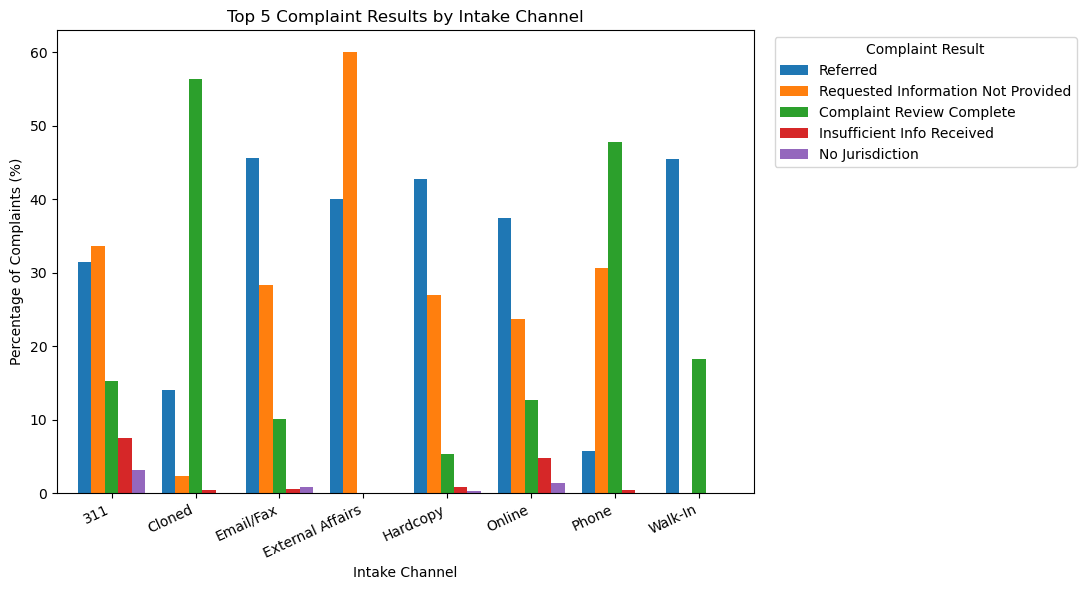

In [45]:



# Identify the five most common results overall
top_results = df["Result"].value_counts().head(5).index

# Calculate percentages within each intake channel
top_data = pd.crosstab(
    df["Intake Channel"],
    df["Result"],
    normalize="index"
) * 100

# Keep only the top five results
top_data = top_data.reindex(columns=top_results, fill_value=0)

# Plot
ax = top_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Top 5 Complaint Results by Intake Channel")
ax.set_xlabel("Intake Channel")
ax.set_ylabel("Percentage of Complaints (%)")
ax.legend(title="Complaint Result", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Insight 
 The chart highlights differences in complaint outcomes across intake channels. Percentages are calculated within each channel, and only the five most common results overall are displayed.


## 2. Complaints by Business Category

### Question
Which business categories have the highest number of consumer complaints?

In [46]:
df["Business Category"].value_counts().head(10)

Business Category
Other                          11105
Misc Non-Food Retail            6077
Tow Truck Company               5587
Restaurant                      3835
Supermarket                     3460
Grocery-Retail                  3367
Home Improvement Contractor     3341
Garage & Parking Lot            3054
Secondhand Dealer - Auto        2422
Tobacco Retail Dealer           2305
Name: count, dtype: int64

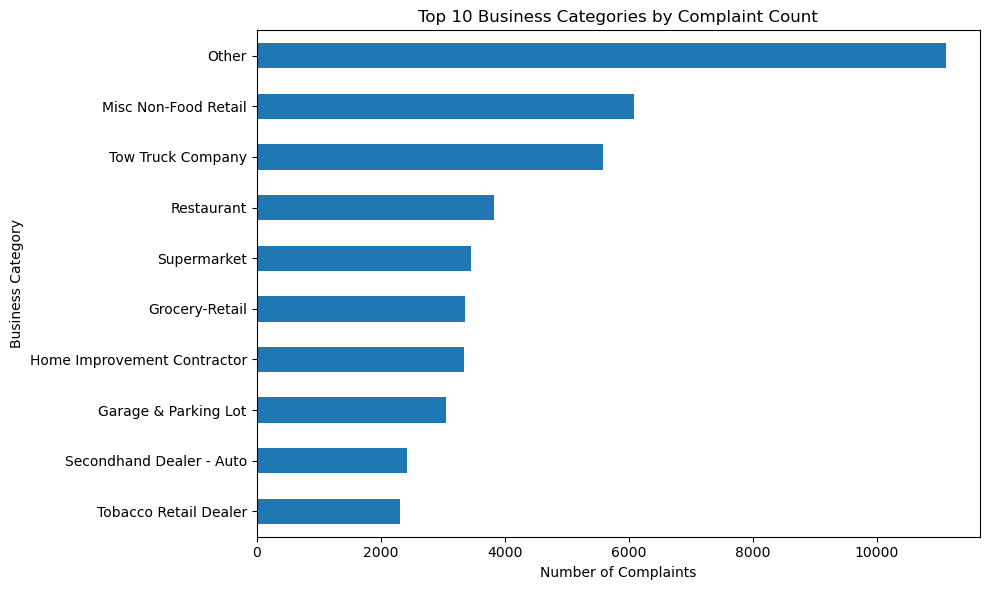

In [47]:
plt.figure(figsize=(10,6))

df["Business Category"].value_counts().head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Business Categories by Complaint Count")
plt.xlabel("Number of Complaints")
plt.ylabel("Business Category")
plt.tight_layout()
plt.show()

### Insight

The *Other* category has the highest number of complaints (11,105), followed by Misc Non-Food Retail and Tow Truck Company. Tobacco Retail Dealer has the lowest complaint count among the top 10 categories shown. This distribution highlights the business categories that account for the largest complaint volumes in the dataset.

## 3. Complaints by Complaint Code

### Question
Which complaint types are most frequently reported by consumers?

In [48]:
df["Complaint Code"].value_counts().head(10)

Complaint Code
Advertising/Misleading - A02    6407
Overcharge                      6288
Unlicensed                      6251
Exchange/Refund/Return          5056
Non-Delivery of Goods - N01     4986
Sidewalk Blocked                3224
Other - Z01                     2945
Billing Dispute - B02           2876
Lost/Stolen/Damaged Property    2329
Damaged Goods - D01             1411
Name: count, dtype: int64

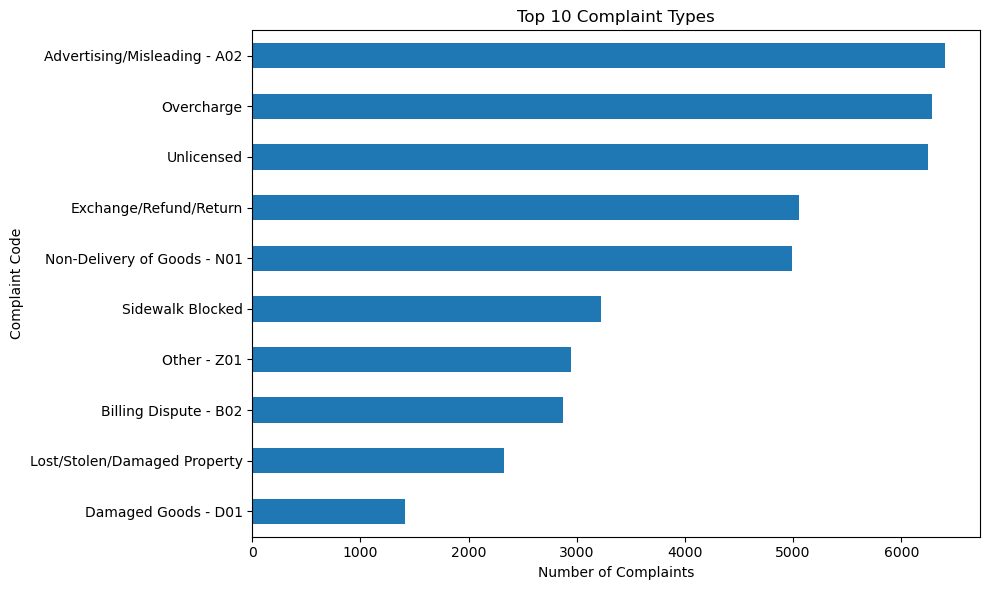

In [49]:
plt.figure(figsize=(10,6))

df["Complaint Code"].value_counts().head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Complaint Types")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Code")
plt.tight_layout()
plt.show()

## 4. Complaints by Result

### Question
What are the most common outcomes recorded for consumer complaints?

In [50]:
df["Result"].value_counts().head(10)

Result
Referred                                 25633
Requested Information Not Provided       23658
Complaint Review Complete                11060
Insufficient Info Received                4885
No Jurisdiction                           1919
Information Provided                      1412
Advised to Sue - ATS                      1302
Duplicate Complaint - DUP                 1051
Resolved and Consumer Satisfied - SPF     1007
No Business Response - NVR                 996
Name: count, dtype: int64

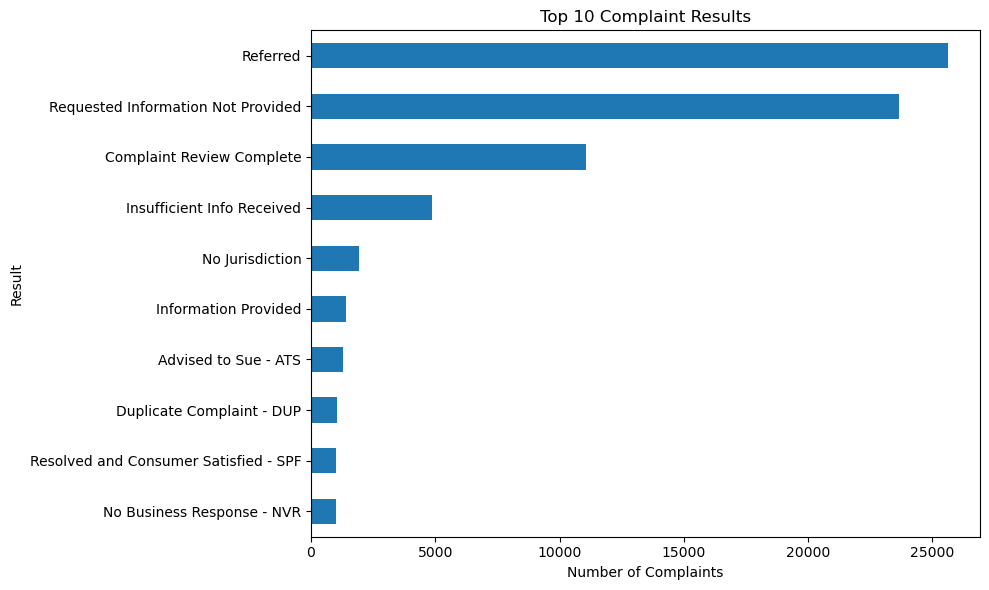

In [51]:
plt.figure(figsize=(10,6))

df["Result"].value_counts().head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Complaint Results")
plt.xlabel("Number of Complaints")
plt.ylabel("Result")
plt.tight_layout()
plt.show()

### Insight

*Referred* is the most common complaint result, with 25,633 complaints, followed closely by *Requested Information Not Provided* (23,658). *Complaint Review Complete* ranks third with 11,060 complaints. Among the top 10 results shown, *No Business Response - NVR* has the lowest count, with 996 complaints.

## 5. Distribution of Refund Amounts

### Question
How are the refund amounts distributed among the complaints?

In [52]:
df['Refund Amount'].value_counts().head(10)

Refund Amount
10000    82
100      27
10       23
50       21
150      20
250      20
1000     20
200      20
500      16
136      16
Name: count, dtype: Int64

In [53]:
df["Refund Amount"].describe()

count         1509.0
mean     1439.477137
std      3422.863772
min              0.0
25%             71.0
50%            220.0
75%            965.0
max          56603.0
Name: Refund Amount, dtype: Float64

In [54]:
(df["Refund Amount"] == 0).sum()

np.int64(3)

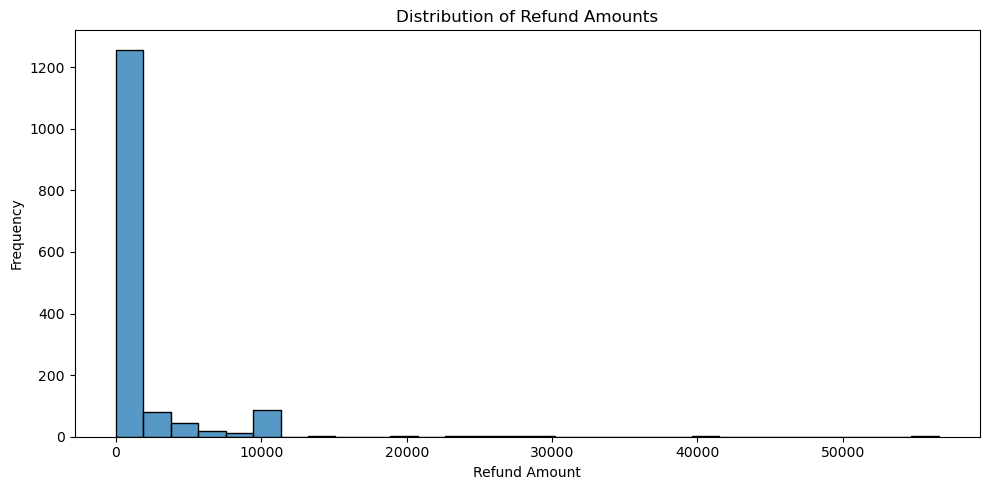

In [55]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Refund Amount"].dropna(),
    bins=30
)

plt.title("Distribution of Refund Amounts")
plt.xlabel("Refund Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Insight

The refund amount distribution is strongly right-skewed, with most observations concentrated in the lower-value ranges and fewer observations at higher amounts. The median refund amount is 220, while the mean is 1,439.48, suggesting that larger refunds raise the average. Only three records have a refund amount of exactly zero, and the maximum recorded amount is 56,603.

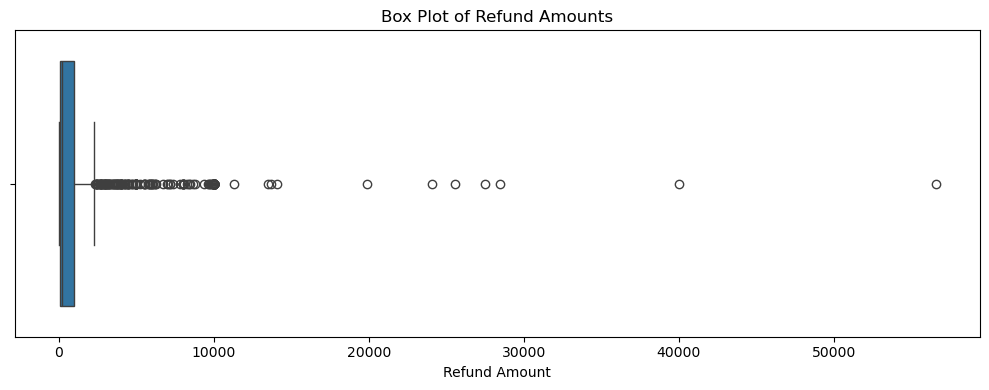

In [56]:
plt.figure(figsize=(10,4))

sns.boxplot(
    x=df["Refund Amount"].dropna()
)

plt.title("Box Plot of Refund Amounts")
plt.xlabel("Refund Amount")
plt.tight_layout()
plt.show()

### Insight

The box plot shows a positively skewed distribution of refund amounts, with several high-value outliers extending far above the upper whisker. The median refund amount is 220, and the middle 50% of refund amounts lie between 71 and 965. These extreme values indicate substantial variation in refund amounts.

In [57]:
Q1 = df["Refund Amount"].quantile(0.25)
Q3 = df["Refund Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Refund Amount"] < lower_bound) |
    (df["Refund Amount"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Percentage of outliers:", round(len(outliers) / df["Refund Amount"].notna().sum() * 100, 2), "%")

Lower bound: -1270.0
Upper bound: 2306.0
Number of outliers: 216
Percentage of outliers: 14.31 %


In [58]:
outliers["Refund Amount"].describe()

count          216.0
mean     7839.310185
std      5719.176039
min           2331.0
25%           4000.0
50%           8000.0
75%          10000.0
max          56603.0
Name: Refund Amount, dtype: Float64

In [59]:
outliers[
    ["Refund Amount", "Business Category", "Complaint Code", "Result"]
].sort_values("Refund Amount", ascending=False).head(10)

,Refund Amount,Business Category,Complaint Code,Result
63988,56603,Secondhand Dealer - Auto,Misrepresentation - M01,Cash Amount - AMT
63447,40000,Home Improvement Contractor,Non-Delivery of Service - N02; Quality of Work...,Cash Amount - AMT
34195,28490,Secondhand Dealer - Auto,Damaged Goods - D01; Defective Goods - D02; Ot...,Cash Amount - AMT
17827,27521,Home Improvement Contractor,Non-Delivery of Service - N02; Exchange/Refund...,Cash Amount - AMT
59259,25563,Garage & Parking Lot,Lost/Stolen/Damaged Property,Cash Amount - AMT
55591,24054,NaN,Exchange Goods/Contract Cancelled - E01,Bill Reduced - BLR
24291,19857,Debt Collection Agency,Billing Dispute - B02,Bill Reduced - BLR
20295,14100,Home Improvement Contractor,Quality of Work - Q01,Goods Repaired - GRS
12650,13700,Debt Collection Agency,Billing Dispute - B02,Bill Reduced - BLR
36995,13500,Secondhand Dealer - Auto,Non-Delivery of Goods - N01,Agency Collected Judgement - ACJ


### Outlier Detection and Treatment

Outliers in the `Refund Amount` column were identified using the Interquartile Range (IQR) method. The lower bound was −1,270 and the upper bound was 2,306. A total of 216 observations (14.31%) were identified as outliers.

The extreme values were inspected along with their business categories, complaint codes, and results. Since the inspection did not establish that these values were incorrect, the outliers were retained to avoid removing potentially valid refund information.

## 6. Complaint Processing Time

### Question
How long does it take to process consumer complaints?

In [60]:
df["Processing Days"] = (
    df["Result Date"] - df["Intake Date"]
).dt.days

print(df["Processing Days"].max())

884.0


In [61]:
df["Processing Days"].max()


884.0

In [62]:
df["Processing Days"].nlargest(5)

4659     884.0
14997    729.0
9260     568.0
70166    558.0
10653    548.0
Name: Processing Days, dtype: float64

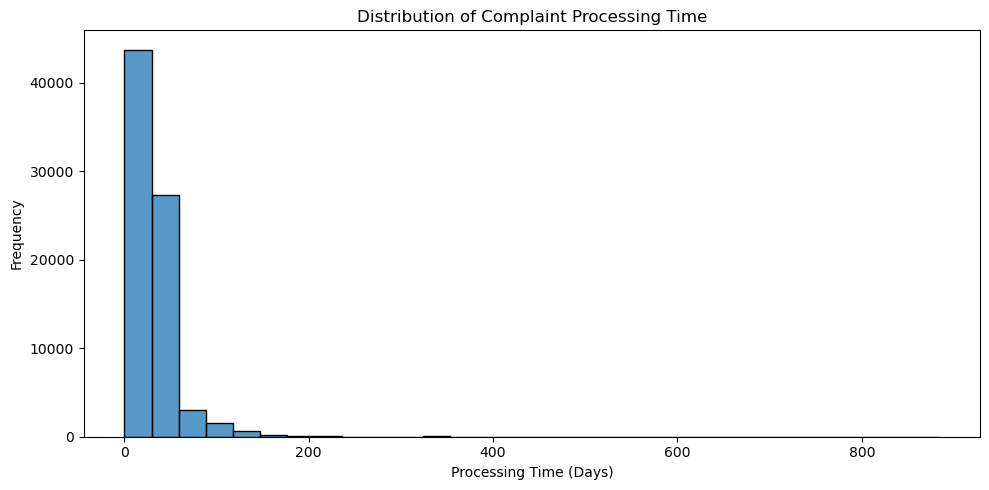

In [63]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Processing Days"].dropna(),
    bins=30
)

plt.title("Distribution of Complaint Processing Time")
plt.xlabel("Processing Time (Days)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

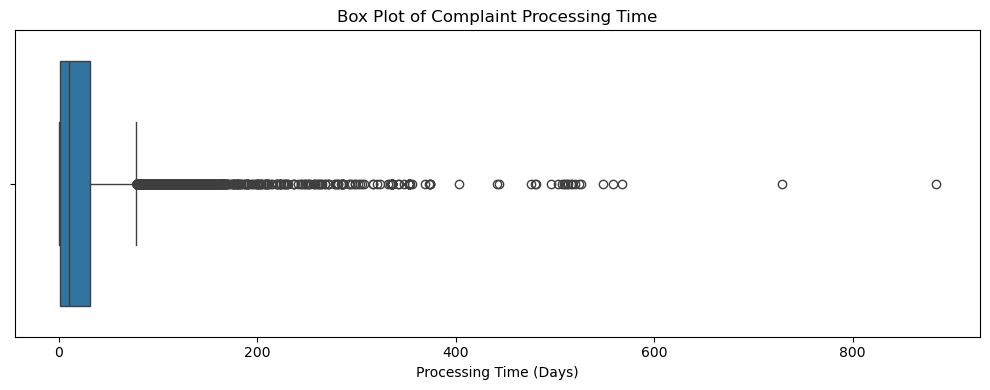

In [64]:
plt.figure(figsize=(10,4))

sns.boxplot(
    x=df["Processing Days"].dropna()
)

plt.title("Box Plot of Complaint Processing Time")
plt.xlabel("Processing Time (Days)")
plt.tight_layout()
plt.show()

The histogram shows a strongly right-skewed distribution of complaint processing times, with most complaints processed within a relatively short period. The box plot identifies numerous outliers representing complaints that took unusually long to process. The maximum recorded processing time was 884 days, indicating substantial variation in processing duration. These extreme values should be investigated but not automatically removed, as they may represent genuine delays.

## 7. Monthly Complaint Trend

### Question
How has the number of consumer complaints changed over time?

In [65]:
monthly_complaints = df.set_index("Intake Date").resample("ME").size()

monthly_complaints

Intake Date
2022-09-30       3
2022-10-31       0
2022-11-30       0
2022-12-31       0
2023-01-31       0
2023-02-28       0
2023-03-31      18
2023-04-30     406
2023-05-31     530
2023-06-30     635
2023-07-31    1980
2023-08-31    2115
2023-09-30    2084
2023-10-31    2181
2023-11-30    2114
2023-12-31    1807
2024-01-31    1852
2024-02-29    1766
2024-03-31    1801
2024-04-30    2099
2024-05-31    2192
2024-06-30    2240
2024-07-31    2263
2024-08-31    2303
2024-09-30    2011
2024-10-31    1933
2024-11-30    1996
2024-12-31    1542
2025-01-31    1791
2025-02-28    1575
2025-03-31    1758
2025-04-30    1853
2025-05-31    2103
2025-06-30    2625
2025-07-31    2688
2025-08-31    2293
2025-09-30    2140
2025-10-31    2155
2025-11-30    1866
2025-12-31    1963
2026-01-31    1996
2026-02-28    1862
2026-03-31    2311
2026-04-30    2331
2026-05-31    2365
2026-06-30    2093
2026-07-31     888
Freq: ME, dtype: int64

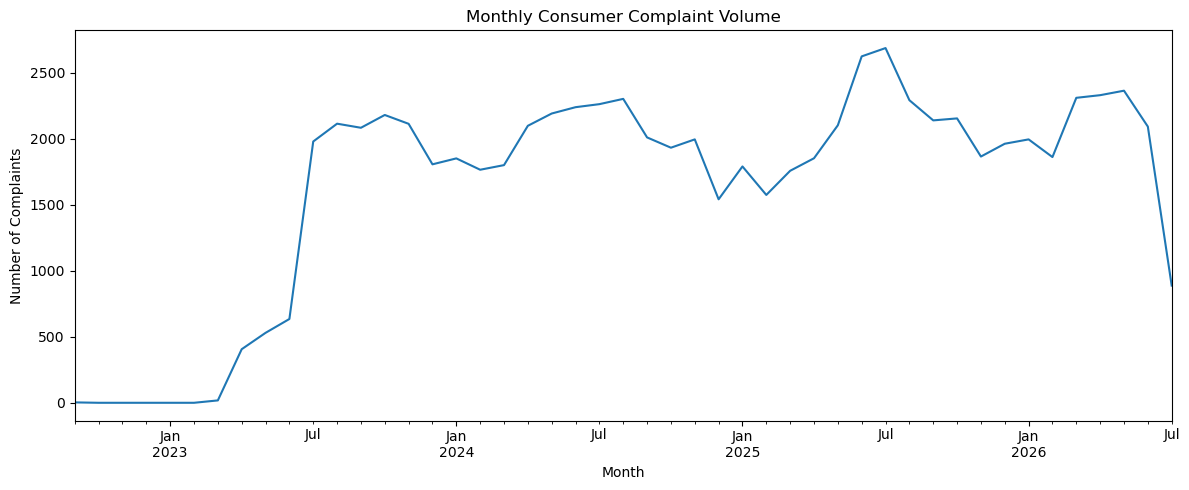

In [66]:
plt.figure(figsize=(12,5))

monthly_complaints.plot(kind="line")

plt.title("Monthly Consumer Complaint Volume")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.show()

The monthly complaint volume shows a clear increase from 2023 onwards, rising from 18 complaints in March 2023 to over 2,000 complaints per month during much of the subsequent period. Complaint volumes generally remained high throughout 2024 and 2025, reaching a peak of 2,688 in July 2025. The monthly counts fluctuated during 2026, reaching 2,365 in May before declining to 888 in July. The lower count in July 2026 may reflect incomplete data for that month and should not automatically be interpreted as a genuine decline in complaints.

## 8. Complaint Results by Intake Channel

### Question
How do complaint outcomes vary across different intake channels?

In [67]:
top_results = df["Result"].value_counts().head(5).index

df_channel_result = df.copy()

df_channel_result["Result Group"] = df_channel_result["Result"].where(
    df_channel_result["Result"].isin(top_results),
    "Other"
)

channel_result = pd.crosstab(
    df_channel_result["Intake Channel"],
    df_channel_result["Result Group"]
)

channel_result

Result Group,Complaint Review Complete,Insufficient Info Received,No Jurisdiction,Other,Referred,Requested Information Not Provided
Intake Channel,,,,,,
311,8193,4025,1657,4855,16930,18111
Cloned,149,1,0,71,37,6
Email/Fax,264,14,23,384,1203,746
External Affairs,0,0,0,0,2,3
Hardcopy,109,17,7,494,886,560
Online,2226,827,232,3526,6556,4157
Phone,117,1,0,38,14,75
Walk-In,2,0,0,4,5,0


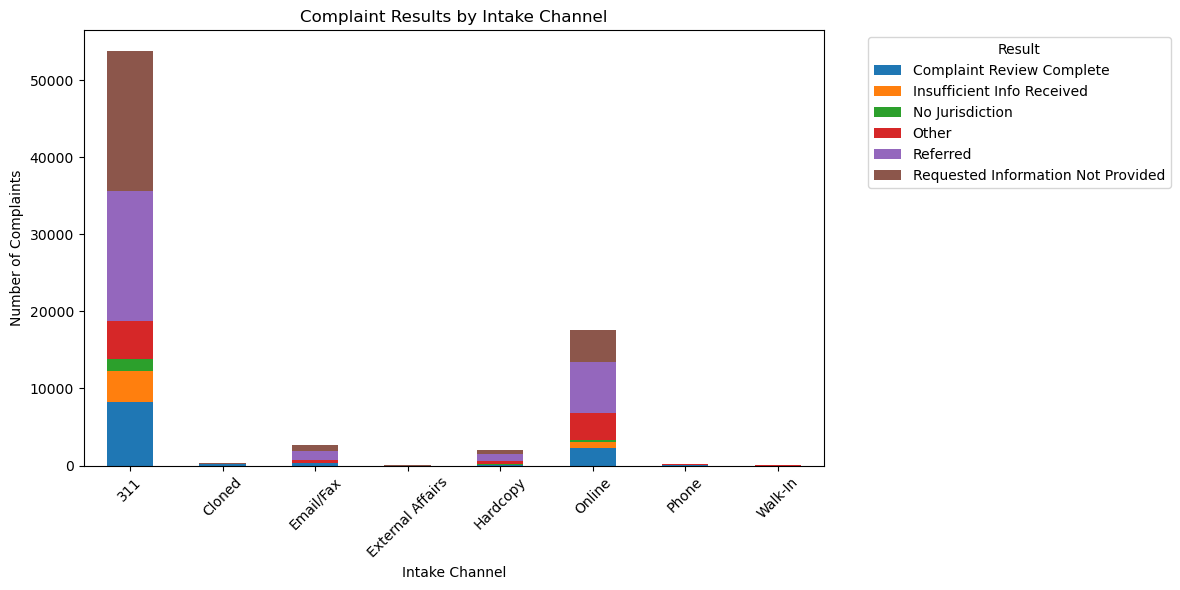

In [68]:
channel_result.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("Complaint Results by Intake Channel")
plt.xlabel("Intake Channel")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.legend(
    title="Result",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

The analysis shows that 311 is the leading intake channel across the dataset, with particularly high counts for “Requested Information Not Provided” (18,111) and “Referred” (16,930). Online complaints also contribute substantially, with “Referred” being the most frequent result (6,556), followed by “Requested Information Not Provided” (4,157). Email/Fax and Hardcopy complaints also show “Referred” as their most common result. Overall, the distribution of complaint results varies across intake channels, while 311 accounts for the largest volume among the channels shown.

## 9. Complaint Results by Business Category

### Question
How do complaint outcomes vary across different business categories?

In [69]:
top_categories = df["Business Category"].value_counts().head(10).index
top_results = df["Result"].value_counts().head(5).index

df_category_result = df.copy()

df_category_result["Result Group"] = df_category_result["Result"].where(
    df_category_result["Result"].isin(top_results),
    "Other"
)

category_result = pd.crosstab(
    df_category_result["Business Category"],
    df_category_result["Result Group"]
).loc[top_categories]

category_result

Result Group,Complaint Review Complete,Insufficient Info Received,No Jurisdiction,Other,Referred,Requested Information Not Provided
Business Category,,,,,,
Other,840,427,506,711,7166,1455
Misc Non-Food Retail,1117,519,463,408,2011,1559
Tow Truck Company,128,421,13,1292,323,3410
Restaurant,705,351,124,432,1022,1201
Supermarket,400,236,115,188,1756,765
Grocery-Retail,635,228,99,256,1433,716
Home Improvement Contractor,445,159,9,969,424,1335
Garage & Parking Lot,202,216,51,522,608,1455
Secondhand Dealer - Auto,103,149,7,410,645,1108


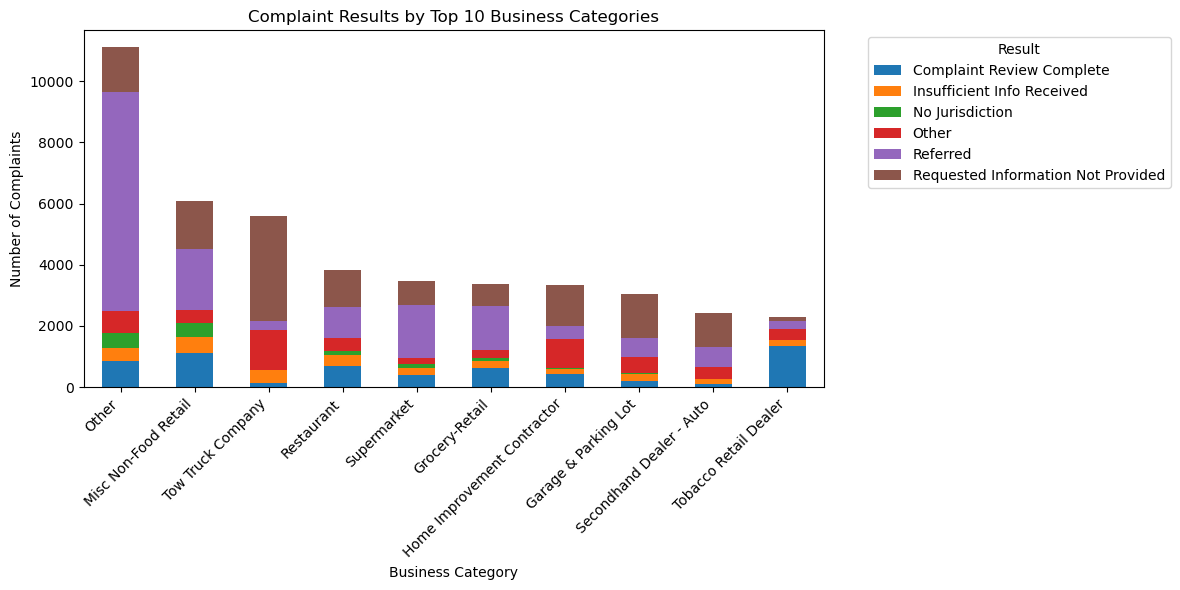

In [70]:
category_result.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("Complaint Results by Top 10 Business Categories")
plt.xlabel("Business Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Result",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

The analysis shows that the “Other” business category has the highest number of complaints resulting in “Referred” (7,166). For Tow Truck Company complaints, “Requested Information Not Provided” is the most frequent result, with 3,410 cases. Misc Non-Food Retail complaints have “Referred” as their most common result (2,011), while Tobacco Retail Dealer complaints show the highest count for “Complaint Review Complete” (1,334) among the listed categories. These patterns indicate that complaint result distributions vary across business categories.


## 10. Complaint Processing Time by Intake Channel

### Question
Does the complaint processing time vary across different intake channels?

In [71]:
df.groupby("Intake Channel")["Processing Days"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Intake Channel,,,,,,,,
311,53770.0,19.48,27.54,0.0,1.0,3.0,31.0,558.0
Cloned,264.0,15.02,26.66,0.0,0.0,0.0,30.0,230.0
Email/Fax,2634.0,19.22,36.58,0.0,0.0,1.0,30.0,568.0
External Affairs,5.0,21.20,20.43,0.0,0.0,30.0,30.0,46.0
Hardcopy,2073.0,21.54,28.09,0.0,0.0,21.0,30.0,503.0
Online,17523.0,28.49,30.45,0.0,6.0,25.0,40.0,884.0
Phone,245.0,24.22,54.89,0.0,0.0,2.0,30.0,510.0
Walk-In,11.0,22.91,32.84,0.0,0.0,0.0,51.0,77.0


In [72]:
df.loc[
    df.groupby("Intake Channel")["Processing Days"].idxmax(),
    ["Intake Channel", "Processing Days"]
].sort_values("Processing Days", ascending=False)

,Intake Channel,Processing Days
4659,Online,884.0
9260,Email/Fax,568.0
70166,311,558.0
73595,Phone,510.0
6143,Hardcopy,503.0
42536,Cloned,230.0
16949,Walk-In,77.0
34024,External Affairs,46.0


In [73]:
print("Missing values:", df["Processing Days"].isna().sum())
print("Negative values:", (df["Processing Days"] < 0).sum())

Missing values: 2
Negative values: 0


In [74]:
df.loc[
    df["Processing Days"].isna(),
    ["Intake Date", "Result Date", "Processing Days"]
]

,Intake Date,Result Date,Processing Days
28866,2024-07-27,NaT,NaN
63892,2023-07-27,NaT,NaN


**Handling Missing Values in Processing Time**

Two records have missing `Result Date` values, resulting in missing `Processing Days`. Since the processing duration cannot be calculated without a result date, these values were retained as missing rather than replaced with zero or an estimated value. The records were retained for other analyses to avoid unnecessary data loss.

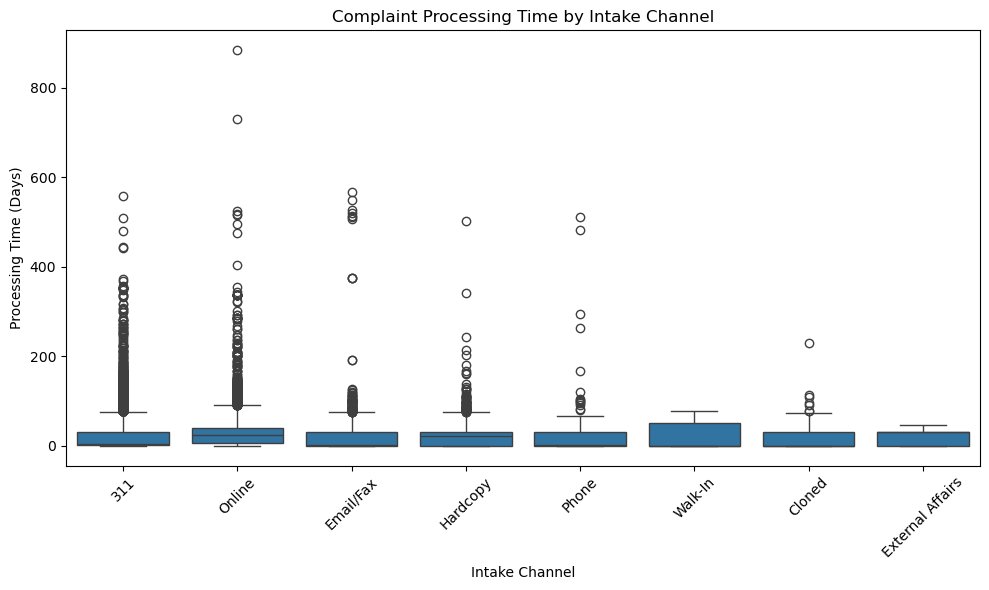

In [75]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="Intake Channel",
    y="Processing Days"
)

plt.title("Complaint Processing Time by Intake Channel")
plt.xlabel("Intake Channel")
plt.ylabel("Processing Time (Days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** The analysis shows variations in complaint processing time across different intake channels. Online complaints have the highest average processing time of 28.49 days and the longest recorded processing time of 884 days. In comparison, complaints received through 311 have an average processing time of 19.48 days and a median of only 3 days. Phone complaints also show considerable variability in processing times. These findings suggest that processing duration varies by intake channel, with some complaints taking considerably longer than others. Two records with missing result dates were excluded from processing-time calculations because their durations could not be determined.

## 11. Processing Time vs Refund Amount

### Question
Is there any relationship between complaint processing time and refund amount?

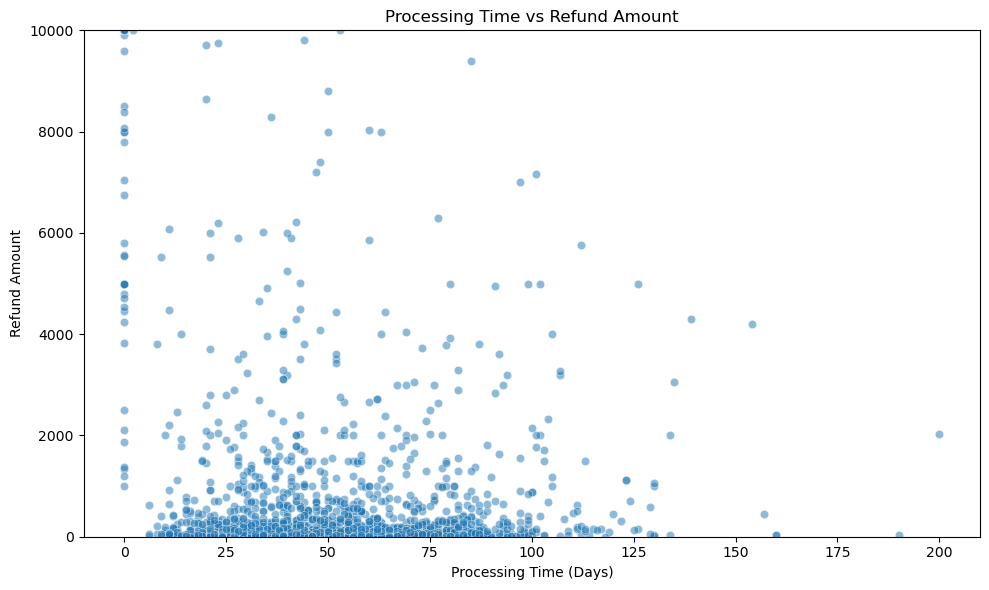

In [76]:

refund_data = df[["Processing Days", "Refund Amount"]].dropna()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=refund_data,
    x="Processing Days",
    y="Refund Amount",
    alpha=0.5
)

plt.title("Processing Time vs Refund Amount")
plt.xlabel("Processing Time (Days)")
plt.ylabel("Refund Amount")
plt.ylim(0, refund_data["Refund Amount"].quantile(0.99))
plt.tight_layout()
plt.show()


**Insight:** The scatter plot shows that most complaints are concentrated at lower refund amounts, across a range of processing times. A few complaints have exceptionally high refund amounts, with the highest exceeding 55,000, while some complaints took more than 150 days to process. The points do not show a clear linear relationship between processing time and refund amount. Further statistical analysis would be required to determine whether an association exists between these variables.

## 12. Complaint Distribution by Borough

### Question
How are consumer complaints distributed across the different boroughs?

In [77]:
borough_counts = df["Borough"].value_counts()

borough_counts

Borough
Manhattan        19712
Brooklyn         19305
Queens           15394
Bronx             9954
Staten Island     1983
Outside NYC        566
Name: count, dtype: int64

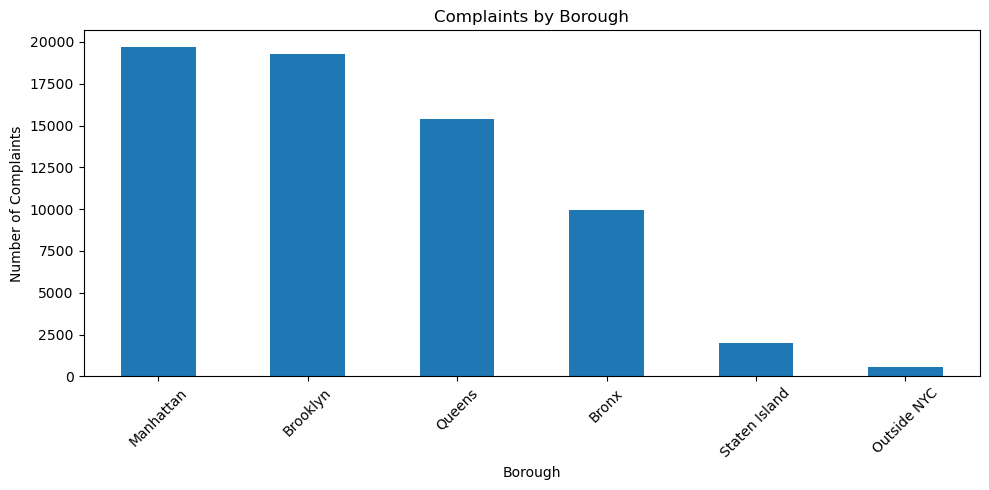

In [78]:
plt.figure(figsize=(10,5))

borough_counts.plot(kind="bar")

plt.title("Complaints by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** Manhattan recorded the highest number of complaints, with 19,712, closely followed by Brooklyn with 19,305. Queens accounted for 15,394 complaints, while the Bronx recorded 9,954. Staten Island had 1,983 complaints, and Outside NYC had the lowest count, with 566. Overall, complaints were concentrated in Manhattan and Brooklyn, while the lower counts in Staten Island and Outside NYC indicate a smaller representation in this dataset.

## 13. Business Category vs Complaint Result

### Question
How are complaint results distributed across the major business categories?

In [79]:
top_categories = df["Business Category"].value_counts().head(10).index

heatmap_data = pd.crosstab(
    df["Business Category"],
    df["Result"]
).loc[top_categories]

heatmap_data

Result,Advised to Sue - ATS,Agency Collected Judgement - ACJ,Bill Reduced - BLR,Business Reported,Cash Amount - AMT,Complaint Invalid - CIN,Complaint Review Complete,Consumer Took Action - CTA,Consumer Withdrew Complaint - CWC,Credit Card Refund and/or Contract Cancelled - CRC,Duplicate Complaint - DUP,Goods Exchanged - GEX,Goods Received - GDR,Goods Repaired - GRS,Information Provided,Inspection Requested,Insufficient Info Received,No Business Response - NVR,No Consumer Response - NCR,No Jurisdiction,No Satisfactory Agreement - NSA,Out of Business - OOB,Provider Feedback Received,Referred,Referred to Hearing - RTH,Referred to Manufacturer - RMF,Referred to Outside - RTO,Requested Information Not Provided,Resolved and Consumer Satisfied - SPF,Store Credit - SCR,Technical Problem,Unable to Locate Business- ULV,Unable to Locate Customer - ULC,Wrong Business and Null and Void - NUL
Business Category,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Other,100,0,8,12,43,5,840,8,6,48,132,2,7,4,58,0,427,83,46,506,30,0,0,7166,0,0,13,1455,93,8,1,2,0,2
Misc Non-Food Retail,36,0,1,2,17,2,1117,2,3,12,42,1,5,0,149,13,519,31,22,463,16,0,0,2011,0,0,9,1559,41,3,0,1,0,0
Tow Truck Company,314,3,3,3,267,7,128,14,3,9,162,0,2,1,13,1,421,153,131,13,49,0,0,323,1,0,62,3410,67,0,0,6,1,20
Restaurant,16,0,0,18,39,1,705,0,3,40,27,0,0,0,44,44,351,36,57,124,5,0,1,1022,0,0,3,1201,90,6,0,1,0,1
Supermarket,8,0,1,6,5,0,400,0,0,5,24,0,0,0,90,12,236,6,10,115,1,0,0,1756,0,0,0,765,14,5,1,0,0,0
Grocery-Retail,8,0,0,8,6,0,635,1,0,10,84,1,0,0,71,17,228,9,9,99,0,0,0,1433,0,0,3,716,23,6,0,0,0,0
Home Improvement Contractor,228,0,6,1,38,5,445,21,4,4,109,0,5,36,9,0,159,201,48,9,67,0,1,424,26,2,39,1335,94,1,0,13,0,11
Garage & Parking Lot,114,0,5,0,91,2,202,9,1,31,43,0,0,6,33,2,216,43,39,51,14,0,0,608,0,0,7,1455,64,11,0,0,0,7
Secondhand Dealer - Auto,86,1,2,2,60,2,103,8,3,9,52,2,2,7,7,6,149,32,39,7,26,0,0,645,0,0,12,1108,46,0,0,1,0,5


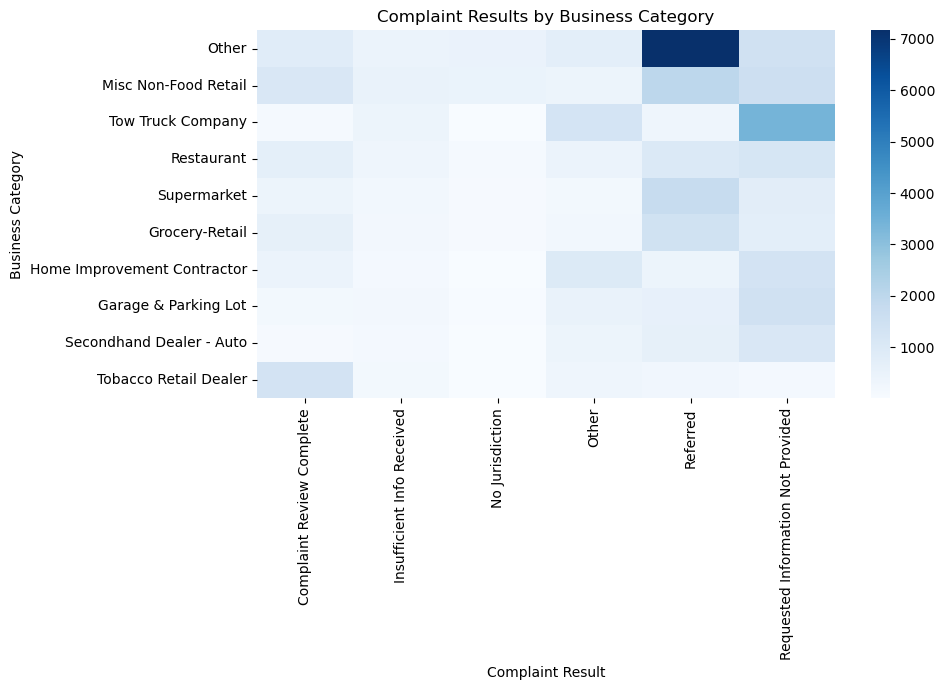

In [80]:

top_categories = df["Business Category"].value_counts().head(10).index
top_results = df["Result"].value_counts().head(5).index

df_heatmap = df.copy()

df_heatmap["Result Group"] = df_heatmap["Result"].where(
    df_heatmap["Result"].isin(top_results),
    "Other"
)

heatmap_data = pd.crosstab(
    df_heatmap["Business Category"],
    df_heatmap["Result Group"]
).loc[top_categories]

plt.figure(figsize=(10, 7))

sns.heatmap(
    heatmap_data,
    annot=False,
    fmt="d",
    cmap="Blues"
)

plt.title("Complaint Results by Business Category")
plt.xlabel("Complaint Result")
plt.ylabel("Business Category")
plt.tight_layout()
plt.show()


**Insight:** The heatmap shows differences in complaint outcomes across business categories. The “Other” business category has the highest count of complaints resulting in “Referred” (7,166). Tow Truck Company complaints are most frequently associated with “Requested Information Not Provided” (3,410), while Misc Non-Food Retail complaints have a high count of “Referred” cases (2,011). Tobacco Retail Dealer complaints show a comparatively high number of “Complaint Review Complete” outcomes (1,334). These patterns indicate that complaint outcomes vary across business categories.

## 14. Complaint Volume by Day of the Week

### Question
On which days of the week are consumer complaints most frequently received?

In [81]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_counts = (
    df["Intake Date"]
    .dt.day_name()
    .value_counts()
    .reindex(day_order)
)

day_counts

Intake Date
Monday       12039
Tuesday      12917
Wednesday    12503
Thursday     12356
Friday       11905
Saturday      7686
Sunday        7121
Name: count, dtype: int64

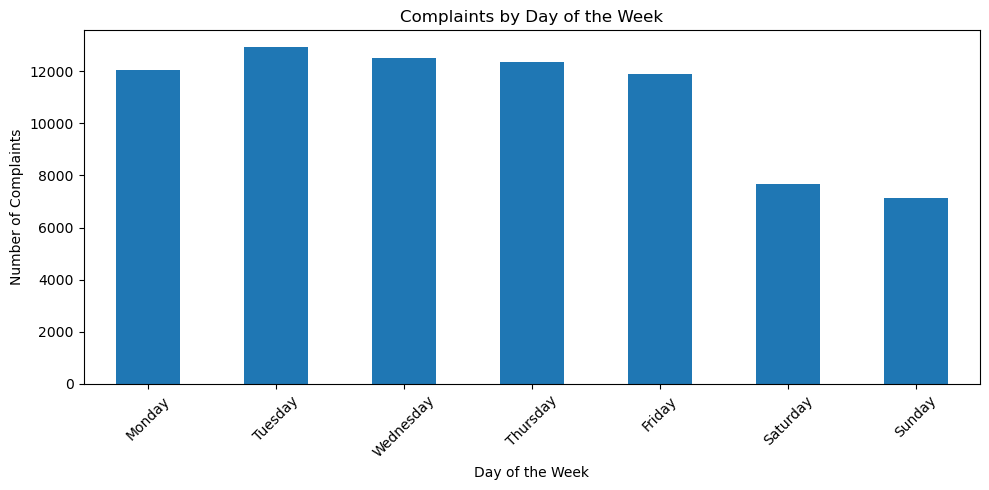

In [82]:
plt.figure(figsize=(10,5))

day_counts.plot(kind="bar")

plt.title("Complaints by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** Tuesday recorded the highest number of complaints, with 12,917, followed by Wednesday with 12,503 and Thursday with 12,356. Monday and Friday also showed relatively high complaint volumes. In contrast, Saturday recorded 7,686 complaints and Sunday had the lowest count, at 7,121. Overall, the dataset shows higher complaint volumes on weekdays than on weekends, suggesting that complaint intake is more concentrated during the working week.

## 15. Refund Amount by Complaint Result

### Question
How do refund amounts vary across different complaint results?

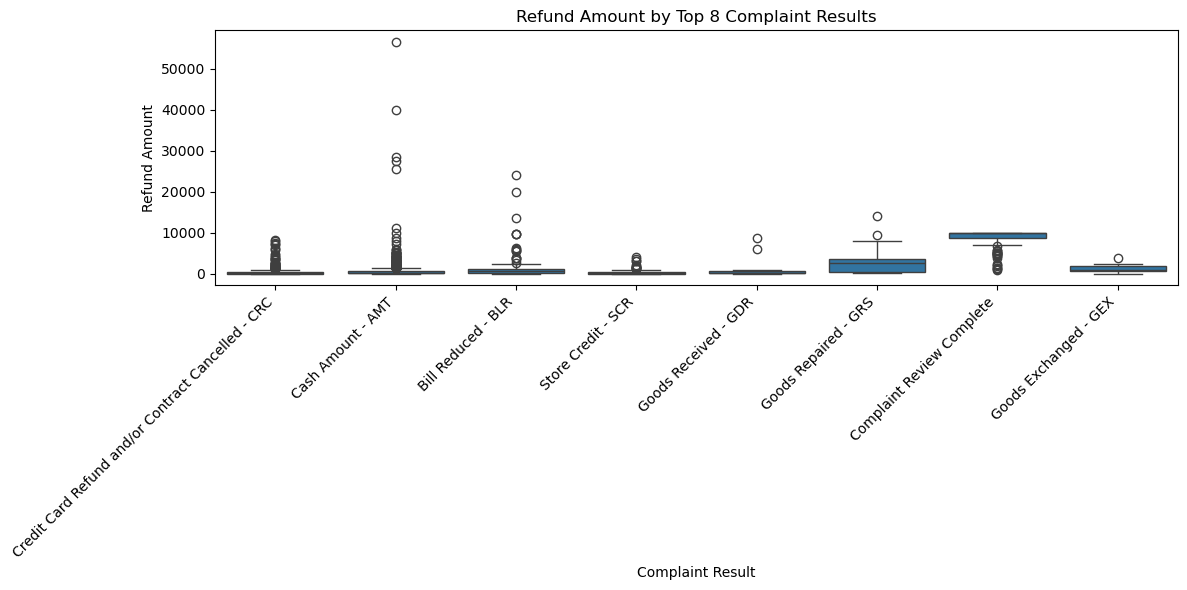

In [83]:

refund_result_data = df[["Result", "Refund Amount"]].dropna()

top_refund_results = (
    refund_result_data["Result"]
    .value_counts()
    .head(8)
    .index
)

plot_data = refund_result_data[
    refund_result_data["Result"].isin(top_refund_results)
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=plot_data,
    x="Result",
    y="Refund Amount"
)

plt.title("Refund Amount by Top 8 Complaint Results")
plt.xlabel("Complaint Result")
plt.ylabel("Refund Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Insight:** The box plot shows substantial variation in refund amounts across different complaint results. The “Cash Amount - AMT” category contains several extreme outliers, including refund amounts exceeding 55,000. “Bill Reduced - BLR” and “Goods Repaired - GRS” also show considerable variation in refund amounts. In contrast, “Complaint Review Complete” has a higher median refund amount than most of the other categories shown. These findings suggest that refund amounts vary depending on the recorded complaint result, with some categories containing unusually high values.

## Interactive Visualisations Using Plotly

Plotly was used to create interactive visualisations to complement the static graphs in the exploratory data analysis. These visualisations allow users to explore complaint trends, compare business categories, and examine the relationship between complaint processing time and refund amount through interactive tooltips and zooming features.

In [84]:
monthly_df = monthly_complaints.rename(
    "Complaint Count"
).reset_index()

monthly_df.columns = ["Month", "Complaint Count"]

fig = px.line(
    monthly_df,
    x="Month",
    y="Complaint Count",
    title="Interactive Monthly Consumer Complaint Trends",
    markers=True,
    labels={
        "Month": "Month",
        "Complaint Count": "Number of Complaints"
    },
    template="plotly_white"
)

fig.update_layout(
    hovermode="x unified",
    xaxis_title="Month",
    yaxis_title="Number of Complaints"
)

fig.show()

**Insight:** The interactive line chart shows the monthly trend in consumer complaints. Complaint volumes increased considerably during 2023 and remained relatively high throughout 2024 and 2025, reaching a peak of 2,688 complaints in July 2025. The chart also allows users to inspect monthly counts in detail. The lower count in July 2026 may reflect incomplete data for that month rather than a definite decline in complaints.

In [85]:
category_counts = (
    df["Business Category"]
    .value_counts()
    .head(10)
    .reset_index()
)

category_counts.columns = ["Business Category", "Complaint Count"]

fig = px.bar(
    category_counts.sort_values("Complaint Count"),
    x="Complaint Count",
    y="Business Category",
    orientation="h",
    title="Interactive Top 10 Business Categories by Complaints",
    labels={
        "Complaint Count": "Number of Complaints",
        "Business Category": "Business Category"
    },
    template="plotly_white",
    color="Complaint Count",
    color_continuous_scale="Blues"
)

fig.update_layout(
    yaxis_title="Business Category",
    xaxis_title="Number of Complaints"
)

fig.show()

**Insight:** The interactive bar chart shows that the “Other” business category recorded the highest number of complaints (11,105), followed by Misc Non-Food Retail (6,077) and Tow Truck Company (5,587). Tobacco Retail Dealer had the lowest complaint count among the ten categories shown, with 2,305 complaints. The interactive tooltips make it easier to compare the complaint counts across categories.

In [86]:
scatter_df = df[
    ["Processing Days", "Refund Amount",
     "Business Category", "Result"]
].dropna()

fig = px.scatter(
    scatter_df,
    x="Processing Days",
    y="Refund Amount",
    hover_data=["Business Category", "Result"],
    title="Interactive Processing Time vs Refund Amount",
    labels={
        "Processing Days": "Processing Time (Days)",
        "Refund Amount": "Refund Amount"
    },
    template="plotly_white",
    opacity=0.6
)

fig.update_layout(
    xaxis_title="Processing Time (Days)",
    yaxis_title="Refund Amount",
    hovermode="closest"
)

fig.show()

**Insight:** The interactive scatter plot shows that most complaints have relatively low refund amounts across a range of processing times. A small number of complaints have exceptionally high refund amounts, including one exceeding 55,000. No clear linear relationship between processing time and refund amount is apparent from the plot. Interactive tooltips allow individual observations to be explored by business category and complaint result.

<h3 style="color:#5B9BD5;">Key Insights from the Analysis</h3>

1. **Complaint distribution across business categories:** The “Other” business category recorded the highest number of complaints, with 11,105 records, followed by Misc Non-Food Retail with 6,077 and Tow Truck Company with 5,587. This suggests that complaint volumes are concentrated in certain business categories, although the broad “Other” category should be interpreted cautiously.

2. **Monthly complaint trends:** Complaint volumes increased substantially during 2023 and remained relatively high through 2024 and 2025. The highest observed monthly count was 2,688 in July 2025. The lower count in July 2026 may reflect incomplete data for that month, so it should not be interpreted as a confirmed decline.

3. **Complaint intake channels and processing time:** Online complaints had an average processing time of approximately 28.49 days, compared with approximately 19.48 days for complaints received through 311. However, the median processing time for 311 complaints was only 3 days, indicating that averages alone do not fully describe the distribution.

4. **Geographical distribution of complaints:** Manhattan recorded 19,712 complaints, closely followed by Brooklyn with 19,305. Queens recorded 15,394 complaints. These differences describe the distribution of complaints in the dataset and do not necessarily indicate differences in the underlying rate of consumer problems, since population, business density and reporting behaviour may vary.

5. **Variation in complaint processing time:** Processing times were highly variable, with some complaints taking hundreds of days to reach a recorded result. The maximum observed processing time was 884 days. Such cases may warrant further investigation to understand whether they represent unusually complex cases, delays or data-quality issues.

6. **Refund amounts and outliers:** Refund amounts were strongly skewed, with most observations concentrated at relatively low values and a small number of exceptionally large amounts. The largest observed refund amount was approximately 56,603. These observations were retained for analysis rather than automatically removed, because extreme values are not necessarily errors.

7. **Complaint activity by day of the week:** Tuesday recorded the highest number of complaints (12,917), while Sunday recorded the lowest (7,121). Complaint counts were generally higher on weekdays than on weekends. This pattern may help describe when complaints are submitted, but it does not by itself explain why the difference occurs.

<h3 style="color:#5B9BD5;">Business Recommendations</h3>

1. **Prioritise high-volume complaint categories:** Consumer-protection teams could review frequently reported business categories, particularly “Other,” Misc Non-Food Retail and Tow Truck Company. The broad “Other” category should be examined further to determine whether its records can be classified more specifically.

2. **Investigate long processing times:** Review cases with unusually long processing durations to identify possible bottlenecks, complex case types or administrative delays. Median processing time and percentile-based measures should be monitored alongside averages to avoid extreme cases distorting performance summaries.

3. **Review online complaint handling:** Since online complaints showed a higher average processing time than 311 complaints in this dataset, compare case complexity, complaint categories and outcomes across intake channels before deciding whether additional resources or workflow improvements are needed.

4. **Monitor unusually large refund amounts:** Validate exceptionally high refund records and investigate whether they reflect legitimate cases, unusual circumstances or data-entry issues. Genuine high-value records should be retained and considered separately when summarising typical refund amounts.

5. **Use geographical patterns to guide further investigation:** Manhattan and Brooklyn had the highest complaint counts in the dataset. Teams could examine complaint types, business density and population-adjusted complaint rates before determining where targeted outreach or enforcement might be most useful.

6. **Develop ongoing monitoring:** Track complaint volumes, processing-time distributions, business categories and complaint outcomes periodically. A dashboard could help identify emerging patterns and monitor whether operational changes are followed by improvements.

<h3 style="color:#5B9BD5;">Conclusion</h3>

This project used Python-based data cleaning, exploratory data analysis, statistical summaries and visualisations to examine consumer complaints. The analysis identified differences in complaint volumes across business categories and locations, changes in monthly complaint counts, variation in processing times and a skewed distribution of refund amounts.

The findings can support further investigation into high-volume complaint categories, long processing durations and unusually large refunds. However, complaint counts and observed associations alone cannot establish the causes of these patterns. Additional information, such as business activity levels, case complexity and population-adjusted rates, would help support more reliable operational decisions.